# 7. 图记忆管理

**`Agent`** 的三种记忆：

- **短期记忆**：通过运行时状态 **`State`** 访问，并由检查点存储器 **`Checkpointer`** 保存，它按照 **`thread_id`** 组织，可以实现线程内的记忆共享。

- **长期记忆**：通过长期记忆存储器 **`Store`** 访问和存储。数据通常按照元组类型的命名空间组织，以键值对的形式存储，提供跨会话的记忆共享。

  - 可以按照命名空间+可选的过滤条件精确检索

  - 也可以通过语义模糊匹配。

- **运行时上下文**：通过上下文对象 **`Context`** 访问，只对本次调用生效，不会被持久化。

  它更适合传递本次运行所需的外部依赖或调用参数，如用户名、模型配置、数据库连接、权限信息等。

我们不止一次提到，**`Agent`** 底层就是一个简易的 **`ReAct`** 架构的 **`LangGraph`** 状态图，所以 **`Agent`** 的记忆机制本质上就是 **`LangGraph`** 状态图的记忆机制。

## 7.1 短期记忆
只要编译图时启用了 **`Checkpointer`**，并且调用图时复用同一个 **`thread_id`**，**`LangGraph`** 就可以在多次调用之间共享同一会话线程下的状态。

## 7.2 长期记忆
长期记忆存储器在编译图时通过 **`store`** 参数传递，图节点中可以通过 **`Runtime`** 对象访问。

### 7.2.1 准备长期记忆
示例:

In [1]:
from langgraph.store.sqlite import SqliteStore
from pathlib import Path
from typing import Final, Tuple
db_path = Path(
    "/Users/skk/Developer/langgraph_learn/data/memory.db"
)

with SqliteStore.from_conn_string(db_path) as store:
    #store.setup()

    namespace = ("users","China")
    # 命名空间 - 层级结构：("users", "用户名")
    # Final 的作用是告诉静态类型检查器，该变量不应该被重新赋值，但 python 运行时不会阻止重新赋值
    # Final 表示“约定为常量、不要再赋值”；
    USERS_NS: Final[Tuple[str]] = ("users", )
    PREFERENCES_KEY: Final[str] = "preferences"

    # 三层: (领域, 用户实体)
    # 每个 key 存储该用户的不同类型数据
    # *USERS_NS 是 在元组字面量里做可迭代解包（PEP 448，Python 3.5+）：把 USERS_NS 这个元组 ("users",) 拆开，把它的元素铺进新元组，再和后面的 "Alice" 拼在一起。
    # 等价于("users", "Alice")。
    namespace1 = (*USERS_NS, "Alice")
    value1 = {
        "course": "计算机组成原理",
        "sports": "跑步",
        "food": "紫光园奶皮子酸奶"
    }

    namespace2 = (*USERS_NS, "Bob")
    value2 = {
        "course": "数字电路与模拟电路",
        "sports": "跑步",
        "food": "奶皮子糖葫芦"
    }

    namespace3 = (*USERS_NS, "Black")
    value3 = {
        "course": "数字电路与模拟电路",
        "sports": "羽毛球",
        "food": "紫光园奶皮子酸奶"
    }

    store.put(namespace1, PREFERENCES_KEY, value1)
    store.put(namespace2, PREFERENCES_KEY, value2)
    store.put(namespace3, PREFERENCES_KEY, value3)

    for item in store.search(USERS_NS):
        print(item)

Item(namespace=['users', 'Alice'], key='preferences', value={'course': '计算机组成原理', 'sports': '跑步', 'food': '紫光园奶皮子酸奶'}, created_at='2026-10-18T07:50:46', updated_at='2026-10-18T07:50:46', score=None)
Item(namespace=['users', 'Black'], key='preferences', value={'course': '数字电路与模拟电路', 'sports': '羽毛球', 'food': '紫光园奶皮子酸奶'}, created_at='2026-10-18T07:50:46', updated_at='2026-10-18T07:50:46', score=None)
Item(namespace=['users', 'Bob'], key='preferences', value={'course': '数字电路与模拟电路', 'sports': '跑步', 'food': '奶皮子糖葫芦'}, created_at='2026-10-18T07:50:46', updated_at='2026-10-18T07:50:46', score=None)


这里使用 **`USERS_NS`** 作为顶层命名空间，`store.search(USERS_NS)` 会查询所有以 **`("users",)`** 开头的记忆数据。返回的每条数据都是一个 **`Item`** 实例。

1. **`(*USERS_NS, "Alice")`** 的写法表示对已有元组进行解包，再拼接新的命名空间片段。
2. 如果希望支持语义检索，需要在 **`Store`** 中配置索引和 **`embedding`** 函数。未配置索引时，**`search()`** 只能按照命名空间和过滤条件检索。

### 7.2.2 访问长期记忆
长期记忆存储器可以通过节点函数中的 **`runtime.store`** 访问。

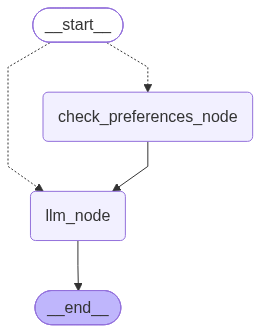

2026-10-18 01:44:30.248 | INFO     | __main__:router:59 - 需要从长期记忆中查询用户偏好
2026-10-18 01:44:30.249 | INFO     | __main__:check_preferences_node:50 - 长期记忆中保存的用户偏好: {'course': '计算机组成原理', 'sports': '跑步', 'food': '紫光园奶皮子酸奶'}


{
    'messages': [
        SystemMessage(
            content='请根据用户偏好解决用户需求',
            additional_kwargs={},
            response_metadata={},
            id='90e1291d-28a3-4cc5-b3d6-4b8195fabc09'
        ),
        HumanMessage(
            content="这是用户的偏好: \n{'course': '计算机组成原理', 'sports': '跑步', 'food': 
'紫光园奶皮子酸奶'}\n这是用户的需求: \n我有点无聊，和我聊聊天吧\n",
            additional_kwargs={},
            response_metadata={},
            id='d882599b-6726-4f52-959b-b9d9051427de'
        ),
        AIMessage(
            content='当然可以！😄\n\n你今天想聊点轻松的，还是来点“计算机组成原理”相关的烧脑话题？  
\n比如我可以陪你聊：\n\n1. **跑步**：最近有没有想跑步？可以一起规划一个轻松的路线或目标。  \n2. 
**美食**：紫光园的奶皮子酸奶听起来就很诱人，你喜欢它的奶香味还是酸甜口感？  \n3. 
**脑洞闲聊**：如果电脑有一天真的产生了意识，它最先会抱怨什么？  
\n\n我先抛个问题：**如果今天不用上课、不用工作，你最想怎么打发一天？**',
            additional_kwargs={'refusal': None},
            response_metadata={
                'token_usage': {
                    'completion_tokens': 410,
                    'prompt_tokens': 150,
                    'total_tokens': 560,
                    'completion_tokens_details': {
                        'accepted_prediction_tokens': None,
                        'audio_tokens': 0,
                        'reasoning_tokens': 0,
                        'rejected_prediction_tokens': None,
                        'text_tokens': 0,
                        'image_tokens': 0
                    },
                    'prompt_tokens_details': {
                        'audio_tokens': 0,
                        'cache_write_tokens': None,
                        'cached_tokens': 0,
                        'image_tokens': 0,
                        'text_tokens': 0
                    },
                    'billing_usage': {
                        'source': 'oai_responses',
                        'semantic': 'openai',
                        'openai_usage': {
                            'prompt_tokens': 0,
                            'completion_tokens': 0,
                            'total_tokens': 560,
                            'prompt_tokens_details': {
                                'cached_tokens': 0,
                                'text_tokens': 0,
                                'audio_tokens': 0,
                                'image_tokens': 0
                            },
                            'completion_tokens_details': {
                                'text_tokens': 0,
                                'audio_tokens': 0,
                                'image_tokens': 0,
                                'reasoning_tokens': 0
                            },
                            'input_tokens': 150,
                            'output_tokens': 410,
                            'input_tokens_details': {
                                'cached_tokens': 0,
                                'text_tokens': 0,
                                'audio_tokens': 0,
                                'image_tokens': 0
                            },
                            'output_tokens_details': {
                                'text_tokens': 0,
                                'audio_tokens': 0,
                                'image_tokens': 0,
                                'reasoning_tokens': 84
                            },
                            'claude_cache_creation_5_m_tokens': 0,
                            'claude_cache_creation_1_h_tokens': 0
                        }
                    },
                    'input_tokens': 150,
                    'output_tokens': 410,
                    'input_tokens_details': None,
                    'claude_cache_creation_5_m_tokens': 0,
                    'claude_cache_creation_1_h_tokens': 0
                },
                'model_provider': 'openai',
                'model_name': 'gpt-6-luna',
                'system_fingerprint': None,
                'id': 'chatcmpl-202610180844312220449208268d9d6a2WFovhz',
                'service_tier': 'default',
                'finish_reason': 'stop',
       

In [3]:
from pathlib import Path

from langgraph.checkpoint.memory import InMemorySaver
from langgraph.graph import MessagesState, StateGraph, START, END
from langgraph.runtime import Runtime
from typing import Literal, TypedDict
from langchain.messages import HumanMessage, ToolMessage, SystemMessage, AIMessage
from langchain.tools import tool
from langchain_openai import ChatOpenAI
import os
from langgraph.checkpoint.sqlite import SqliteSaver
from loguru import logger
from rich import print as rprint
from random import randint
from dotenv import load_dotenv
from IPython.display import display
# 从.env文件中加载环境变量
load_dotenv(override=True, verbose=True,dotenv_path="/Users/skk/Developer/lang-chain-learn/conf/.env")

OPENAI_API_KEY = os.environ["OPENAI_API_KEY"]
OPENAI_API_BASE = os.environ["OPENAI_API_BASE"]  # 与本项目 .env 中的名称一致

model = ChatOpenAI(
    model="gpt-6-luna",  # 当前配置已验证可用；原 gpt-5.5 返回模型权限 403
    api_key=OPENAI_API_KEY,
    base_url=OPENAI_API_BASE,
)

class OverAllState(MessagesState):
    username: str
    user_input: str
    output: str
    preferences: dict[str, str] # 用户偏好

def check_preferences_node(state: OverAllState, runtime: Runtime) -> OverAllState:
    # 从短期记忆中获取用户名
    username = state["username"]
    # 获取长期记忆存储器 store
    store = runtime.store

    # 根据用户信息拼接命名空间，查询用户偏好
    namespace = (*USERS_NS, username)
    key = PREFERENCES_KEY
    item = store.get(namespace, key)

    if not item:
        logger.warning("长期记忆中没有 {} 的偏好数据", username)
        return {}

    logger.info("长期记忆中保存的用户偏好: {}", item.value)
    return {
        "preferences": item.value
    }#存储到短期记忆中

# 路由函数，如果状态中没有用户偏好，则从长期记忆中查询，否则直接执行模型节点
def router(state: OverAllState) -> Literal["check_preferences_node", "llm_node"]:
    # 短期记忆里没有偏好
    if not state.get("preferences"):
        logger.info("需要从长期记忆中查询用户偏好")
        return "check_preferences_node"#没有偏好去长期记忆里查
    logger.info("用户偏好已存在，不必查询")
    return "llm_node"

def llm_node(state: OverAllState) -> OverAllState:
    # 长期记忆中未必有用户偏好
    preferences = state.get("preferences", {})
    user_input = state["user_input"]
    human_prompt = (f"这是用户的偏好: \n{preferences}\n"
              f"这是用户的需求: \n{user_input}\n")
    system_prompt = "请根据用户偏好解决用户需求"

    # 获取历史消息列表，如果历史为空则初始化系统提示词
    messages: list[SystemMessage | HumanMessage | AIMessage | ToolMessage] = [
        SystemMessage(content=system_prompt)
    ] if not state.get("messages", []) else state["messages"]

    model_response = model.invoke(messages + [HumanMessage(content=human_prompt)])
    output = model_response.content

    return {
        "messages": messages + [HumanMessage(content=human_prompt), model_response],
        "output": output
    }



builder = StateGraph(state_schema=OverAllState)
builder.add_node("check_preferences_node", check_preferences_node)
builder.add_node("llm_node", llm_node)
builder.add_conditional_edges(START, router, path_map=["check_preferences_node", "llm_node"])
builder.add_edge("check_preferences_node", "llm_node")
builder.add_edge("llm_node", END)

db_path = Path(
    "/Users/skk/Developer/langgraph_learn/data/memory.db"
)

with SqliteStore.from_conn_string(db_path) as store, \
     SqliteSaver.from_conn_string(db_path) as checkpointer:
    graph = builder.compile(checkpointer=checkpointer, store=store)
    
    display(graph)

    config = {"configurable": {"thread_id": "345"}}
    res = graph.invoke({"username": "Alice", "user_input": "我有点无聊，和我聊聊天吧"}, config=config)
    rprint(res)

In [ ]:
with SqliteStore.from_conn_string(db_path) as store, \
     SqliteSaver.from_conn_string(db_path) as checkpointer:
    graph = builder.compile(checkpointer=checkpointer, store=store)
    new_res = graph.invoke({"user_input": "推荐一下酸奶"}, config=config)
    # 将new_res的messages删除 ,把该键对应的值（也就是消息列表）返回，赋值给 new_messages。
    new_messages = new_res.pop("messages")
    rprint(new_messages)

2026-10-18 01:55:43.502 | INFO     | __main__:router:61 - 用户偏好已存在，不必查询


[
    SystemMessage(
        content='请根据用户偏好解决用户需求',
        additional_kwargs={},
        response_metadata={},
        id='90e1291d-28a3-4cc5-b3d6-4b8195fabc09'
    ),
    HumanMessage(
        content="这是用户的偏好: \n{'course': '计算机组成原理', 'sports': '跑步', 'food': 
'紫光园奶皮子酸奶'}\n这是用户的需求: \n我有点无聊，和我聊聊天吧\n",
        additional_kwargs={},
        response_metadata={},
        id='d882599b-6726-4f52-959b-b9d9051427de'
    ),
    AIMessage(
        content='当然可以！😄\n\n你今天想聊点轻松的，还是来点“计算机组成原理”相关的烧脑话题？  
\n比如我可以陪你聊：\n\n1. **跑步**：最近有没有想跑步？可以一起规划一个轻松的路线或目标。  \n2. 
**美食**：紫光园的奶皮子酸奶听起来就很诱人，你喜欢它的奶香味还是酸甜口感？  \n3. 
**脑洞闲聊**：如果电脑有一天真的产生了意识，它最先会抱怨什么？  
\n\n我先抛个问题：**如果今天不用上课、不用工作，你最想怎么打发一天？**',
        additional_kwargs={'refusal': None},
        response_metadata={
            'token_usage': {
                'completion_tokens': 410,
                'prompt_tokens': 150,
                'total_tokens': 560,
                'completion_tokens_details': {
                    'accepted_prediction_tokens': None,
                    'audio_tokens': 0,
                    'reasoning_tokens': 0,
                    'rejected_prediction_tokens': None,
                    'text_tokens': 0,
                    'image_tokens': 0
                },
                'prompt_tokens_details': {
                    'audio_tokens': 0,
                    'cache_write_tokens': None,
                    'cached_tokens': 0,
                    'image_tokens': 0,
                    'text_tokens': 0
                },
                'billing_usage': {
                    'source': 'oai_responses',
                    'semantic': 'openai',
                    'openai_usage': {
                        'prompt_tokens': 0,
                        'completion_tokens': 0,
                        'total_tokens': 560,
                        'prompt_tokens_details': {
                            'cached_tokens': 0,
                            'text_tokens': 0,
                            'audio_tokens': 0,
                            'image_tokens': 0
                        },
                        'completion_tokens_details': {
                            'text_tokens': 0,
                            'audio_tokens': 0,
                            'image_tokens': 0,
                            'reasoning_tokens': 0
                        },
                        'input_tokens': 150,
                        'output_tokens': 410,
                        'input_tokens_details': {
                            'cached_tokens': 0,
                            'text_tokens': 0,
                            'audio_tokens': 0,
                            'image_tokens': 0
                        },
                        'output_tokens_details': {
                            'text_tokens': 0,
                            'audio_tokens': 0,
                            'image_tokens': 0,
                            'reasoning_tokens': 84
                        },
                        'claude_cache_creation_5_m_tokens': 0,
                        'claude_cache_creation_1_h_tokens': 0
                    }
                },
                'input_tokens': 150,
                'output_tokens': 410,
                'input_tokens_details': None,
                'claude_cache_creation_5_m_tokens': 0,
                'claude_cache_creation_1_h_tokens': 0
            },
            'model_provider': 'openai',
            'model_name': 'gpt-6-luna',
            'system_fingerprint': None,
            'id': 'chatcmpl-202610180844312220449208268d9d6a2WFovhz',
            'service_tier': 'default',
            'finish_reason': 'stop',
            'logprobs': None
        },
        id='lc_run--01a14e2f-12aa-7bf2-99c4-cac891f80115-0',
        tool_calls=[],
        invalid_tool_calls=[],
        usage_metadata={
            'input_tokens': 150,
            'output_tokens': 410,
            'total_tokens': 560,
            'input_token_details': {'audio': 0, 'cache_read': 0},
            'ou

**运行流程如下**：

1. 第一次调用时，状态中还没有 **`preferences`**。
2. 路由函数会路由至 **`check_preferences_node`**。
3. **`check_preferences_node`** 从长期记忆存储器中读取用户偏好。
4. 读取到的偏好会写入图状态，成为当前会话线程中的短期记忆。
5. 后续节点可以直接从状态中读取 **`preferences`**。
6. 第二次运行前，状态中已经包含：

    * **`username`**
    * **`preferences`**
    * **`messages`**
    * 上一次调用生成的 **`output`**

因此，本次调用不会重新访问长期记忆存储器，而是直接复用当前会话状态中缓存的用户偏好。

这正是短期记忆和长期记忆协作的典型模式：

> 第一次调用从长期记忆中读取数据，并写入短期记忆；后续同一会话线程内优先复用短期记忆，避免重复查询长期记忆。

## 7.3 运行时上下文

在某些场景下，我们希望在调用图时传入一些**仅对当次调用有效**的信息，比如当前登录用户、请求来源、调用方标识等。这些信息不适合放入图状态（图状态会被持久化并在同一会话中跨调用共享），而应该通过**运行时上下文（Runtime Context）**传递。

这种Runtime Context的特点是:
> 仅对本次调用生效，不会被持久化，也不会在同一会话的下一次调用中自动恢复。

定义方式:
1. 初始化状态图时，使用 **`context_schema`** 定义上下文类型。
2. 调用图时通过 **`context`** 参数传入上下文对象。
3. 节点或路由函数中通过 **`runtime.context`** 访问上下文。

### 7.3.1 访问运行时上下文
下面通过一个简单的客服机器人案例演示运行时上下文的用法。

**场景**：不同的用户调用同一个机器人，机器人根据运行时上下文中的**用户名**和**会员等级**，生成不同风格的回复。

In [6]:
from pathlib import Path
from dataclasses import dataclass
from langgraph.graph import MessagesState, StateGraph, START, END
from langgraph.runtime import Runtime
from typing import Literal, TypedDict
from langchain.messages import HumanMessage, ToolMessage, SystemMessage, AIMessage
from langchain.tools import tool
from langchain_openai import ChatOpenAI
import os
from langgraph.checkpoint.sqlite import SqliteSaver
from loguru import logger
from rich import print as rprint
from random import randint
from dotenv import load_dotenv
from IPython.display import display
# 从.env文件中加载环境变量
load_dotenv(override=True, verbose=True,dotenv_path="/Users/skk/Developer/lang-chain-learn/conf/.env")

OPENAI_API_KEY = os.environ["OPENAI_API_KEY"]
OPENAI_API_BASE = os.environ["OPENAI_API_BASE"]  # 与本项目 .env 中的名称一致

model = ChatOpenAI(
    model="gpt-6-luna",  # 当前配置已验证可用；原 gpt-5.5 返回模型权限 403
    api_key=OPENAI_API_KEY,
    base_url=OPENAI_API_BASE,
)

# 1. 定义运行时上下文类型
@dataclass
class UserContext:
    username: str
    membership_level: str  # "普通用户" / "VIP"

# 2. 定义图状态
class OverAllState(MessagesState):
    user_input: str
    output: str

# 3. 定义节点：通过 runtime.context 访问运行时上下文
def llm_node(state: OverAllState, runtime: Runtime[UserContext]) -> OverAllState:
    runtime_context = runtime.context

    if runtime_context:
        username = runtime_context.username
        level = runtime_context.membership_level
        logger.info(f"当前用户: {username}, 会员等级: {level}")

        if level == "VIP":
            system_prompt = f"你是高级客服助理。当前VIP用户是{username}，请使用尊称'您'，语气热情周到，回复末尾加上'�️VIP专属服务'。"
        else:
            system_prompt = f"你是普通客服助理。当前用户是{username}，请友好简洁地回复。"
    else:
        logger.warning("运行时上下文为空，使用默认风格")
        system_prompt = "你是客服助理，请友好简洁地回复。"

    user_input = state["user_input"]
    messages = state.get("messages", [])
    response = model.invoke(
        [HumanMessage(content=system_prompt)] +
        messages +
        [HumanMessage(content=user_input)]
    )

    return {
        "messages": [response],
        "output": response.content
    }

# 4. 构建图，传入 context_schema
builder = StateGraph(state_schema=OverAllState, context_schema=UserContext)
builder.add_node("llm_node", llm_node)
builder.add_edge(START, "llm_node")
builder.add_edge("llm_node", END)

graph = builder.compile()

config = {"configurable": {"thread_id": "demo-7.3"}}
res = graph.invoke(
    {"user_input": "你好，帮我查一下最近有什么优惠活动"},
    config=config,
    context=UserContext(username="Alice", membership_level="VIP")
)

rprint(res)


2026-10-18 02:22:15.865 | INFO     | __main__:llm_node:46 - 当前用户: Alice, 会员等级: VIP


{
    'messages': [
        AIMessage(
            content='您好，Alice！目前我这里没有实时优惠活动信息，暂时无法确认最近有哪些活动。您可以告诉我想了解哪
类商品或服务，我会帮您查找相关信息。🛎️VIP专属服务',
            additional_kwargs={'refusal': None},
            response_metadata={
                'token_usage': {
                    'completion_tokens': 53,
                    'prompt_tokens': 4443,
                    'total_tokens': 4496,
                    'completion_tokens_details': None,
                    'prompt_tokens_details': {
                        'audio_tokens': None,
                        'cache_write_tokens': None,
                        'cached_tokens': 4224,
                        'image_tokens': None,
                        'text_tokens': None
                    }
                },
                'model_provider': 'openai',
                'model_name': 'gpt-6-luna',
                'system_fingerprint': None,
                'id': 'resp_01b177b1128bcff6016ad48fcaf0c0819195aaa33c29a1f392',
                'service_tier': 'default',
                'finish_reason': 'stop',
                'logprobs': None
            },
            id='lc_run--01a14e51-a4ba-7c53-934c-6480dd3cfb00-0',
            tool_calls=[],
            invalid_tool_calls=[],
            usage_metadata={
                'input_tokens': 4443,
                'output_tokens': 53,
                'total_tokens': 4496,
                'input_token_details': {'cache_read': 4224},
                'output_token_details': {}
            }
        )
    ],
    'user_input': '你好，帮我查一下最近有什么优惠活动',
    'output': 
'您好，Alice！目前我这里没有实时优惠活动信息，暂时无法确认最近有哪些活动。您可以告诉我想了解哪类商品或服务，我会帮
您查找相关信息。🛎️VIP专属服务'
}

In [7]:
# === 第二次调用：不传运行时上下文 ===
print("=" * 30, "第二次调用：不传上下文", "=" * 30)
res2 = graph.invoke(
    {"user_input": "再帮我看看有没有新品"},
    config=config
)
rprint(res2)

2026-10-18 02:22:42.781 | WARNING  | __main__:llm_node:53 - 运行时上下文为空，使用默认风格


============================== 第二次调用：不传上下文 ==============================


{
    'messages': [
        AIMessage(
            content='当然可以！请告诉我你想看哪个品类或品牌的新品？',
            additional_kwargs={'refusal': None},
            response_metadata={
                'token_usage': {
                    'completion_tokens': 61,
                    'prompt_tokens': 422,
                    'total_tokens': 483,
                    'completion_tokens_details': {
                        'accepted_prediction_tokens': None,
                        'audio_tokens': 0,
                        'reasoning_tokens': 0,
                        'rejected_prediction_tokens': None,
                        'text_tokens': 0,
                        'image_tokens': 0
                    },
                    'prompt_tokens_details': {
                        'audio_tokens': 0,
                        'cache_write_tokens': None,
                        'cached_tokens': 0,
                        'image_tokens': 0,
                        'text_tokens': 0
                    },
                    'billing_usage': {
                        'source': 'oai_responses',
                        'semantic': 'openai',
                        'openai_usage': {
                            'prompt_tokens': 0,
                            'completion_tokens': 0,
                            'total_tokens': 483,
                            'prompt_tokens_details': {
                                'cached_tokens': 0,
                                'text_tokens': 0,
                                'audio_tokens': 0,
                                'image_tokens': 0
                            },
                            'completion_tokens_details': {
                                'text_tokens': 0,
                                'audio_tokens': 0,
                                'image_tokens': 0,
                                'reasoning_tokens': 0
                            },
                            'input_tokens': 422,
                            'output_tokens': 61,
                            'input_tokens_details': {
                                'cached_tokens': 0,
                                'text_tokens': 0,
                                'audio_tokens': 0,
                                'image_tokens': 0
                            },
                            'output_tokens_details': {
                                'text_tokens': 0,
                                'audio_tokens': 0,
                                'image_tokens': 0,
                                'reasoning_tokens': 38
                            },
                            'claude_cache_creation_5_m_tokens': 0,
                            'claude_cache_creation_1_h_tokens': 0
                        }
                    },
                    'input_tokens': 422,
                    'output_tokens': 61,
                    'input_tokens_details': None,
                    'claude_cache_creation_5_m_tokens': 0,
                    'claude_cache_creation_1_h_tokens': 0
                },
                'model_provider': 'openai',
                'model_name': 'gpt-6-luna',
                'system_fingerprint': None,
                'id': 'chatcmpl-202610180922436877836398268d9d6M7ZcpJLe',
                'service_tier': 'default',
                'finish_reason': 'stop',
                'logprobs': None
            },
            id='lc_run--01a14e52-0dde-7802-b0c1-e7eed6058e1a-0',
            tool_calls=[],
            invalid_tool_calls=[],
            usage_metadata={
                'input_tokens': 422,
                'output_tokens': 61,
                'total_tokens': 483,
                'input_token_details': {'audio': 0, 'cache_read': 0},
                'output_token_details': {'audio': 0, 'reasoning': 0}
            }
        )
    ],
    'user_input': '再帮我看看有没有新品',
    'output': '当然可以！请告诉我你想看哪个品类或品牌的新品？'
}

[中间件langchain里也有使用](/Users/skk/Developer/lang-chain-learn/Chapter08_Middleware/07-自定义中间件.ipynb)

1. **第一次调用**传入了 **`context=UserContext(username=”Alice”, membership_level=”VIP”)`**，节点通过 **`runtime.context`** 读取到用户名和会员等级，生成了VIP风格的回复，末尾带上了 **`�️VIP专属服务`** 标识。

2. **第二次调用**使用了相同的 **`thread_id`**，但没有传入 **`context`**。此时 **`runtime.context`** 为 **`None`**，节点走入了默认风格分支，回复中不再有VIP标识。

这个对比可以清晰地看到：

> **运行时上下文仅对当次调用生效，不会被持久化。即使使用相同的 `thread_id`，下一次调用也不会自动继承上一次的上下文。**

### 7.3.2 总结

运行时上下文适合传递以下信息：

| 适合放入运行时上下文           | 不适合（应放入图状态）       |
| ------------------------------ | ---------------------------- |
| 当前登录用户信息               | 需要在多轮对话间共享的数据   |
| 请求来源（Web / API / 小程序） | 需要在检查点中恢复的执行进度 |
| 调用方标识、Trace ID           | 需要跨调用持久化的业务数据   |
| 本次调用的功能开关             | 节点间需要传递的计算结果     |

简单来说：

> **跨调用共享、需要持久化的数据 → 放入 State；仅当次调用有效的信息 → 放入 Runtime Context。**

# 总结
这部分直接看文档，总结地很好。

1. 节点可以是同步或异步 **`Python`** 函数,除此之外，节点也可以是符合要求的其他可调用对象或 **`Runnable`** 实例。 但从源码实现角度看，节点最终会被转换或包装为可运行对象，并作为 **`PregelNode.bound`** 保存。

2. 普通图节点通常使用以下四个参数：
    * **`state`**：输入节点的图状态。**`state`** 是位置传参，因此参数名称不重要，但通常约定命名为 **`state`**
    * **`config`**：状态图的运行时配置，它是一个 **`RunnableConfig`** 实例，底层运行时在节点函数执行前通过关键字传参动态注入。

- 可以通过 **`config`** 访问当前线程的 **`thread_id`**、超步序号、递归限制等配置信息。如下

  ```python
  config["configurable"]["thread_id"] 
  config["recursion_limit"]
  config["metadata"]
  ```

- **`runtime`**：状态图的运行时对象，可以通过它访问运行时上下文、长期记忆存储器等信息。底层运行时在节点函数执行前通过关键字传参动态注入。

- **`writer`**：流式写入器，通常用于自定义流式输出。详见流处理章节。

典型写法如下： 

```python
def node(state: State, config: RunnableConfig, runtime: Runtime[Context]) -> State:
    ...
```

* 编译图时传入 **`checkpointer`**，并在调用时传入 **`config`**，可以在节点中通过 **`config`** 间接访问当前调用的配置信息，如 **`thread_id`**。
* 编译图时传入 **`store`** 后，可以在节点中通过 **`runtime.store`** 访问长期记忆存储器。
* 初始化状态图时传入 **`context_schema`**，并在调用时传入 **`context`** 后，可以在节点中通过 **`runtime.context`** 访问运行时上下文。

# 问题

### 1. 上下文管理器语法为什么可以连起来定义


**`from_conn_string` 被 `@contextmanager` 装饰，调用它返回的就是上下文管理器**

`SqliteSaver` / `SqliteStore` 的 `from_conn_string` 是 `@contextmanager` 装饰的类方法，内部大致是：

```python
@classmethod
@contextmanager
def from_conn_string(cls, conn_string):
    conn = sqlite3.connect(conn_string, check_same_thread=False)
    try:
        yield cls(conn)      # 产出真正的实例给 as 变量
    finally:
        conn.close()         # 退出 with 时关闭连接
```

- `yield` 之前的代码相当于 `__enter__`（建立连接）；
- `yield` 的值绑定给 `as` 后的变量（真正的 `SqliteSaver` / `SqliteStore` 实例）；
- `yield` 之后的 `finally` 相当于 `__exit__`（关闭连接）。

**`with A as a, B as b:` 等价于嵌套 `with`**

逗号连接多个上下文管理器，从左到右依次进入，退出时按逆序（后进先出）：

```python
with SqliteStore.from_conn_string(db_path) as store, \
     SqliteSaver.from_conn_string(db_path) as checkpointer:
    ...
# 等价于
with SqliteStore.from_conn_string(db_path) as store:
    with SqliteSaver.from_conn_string(db_path) as checkpointer:
        ...
```

末尾的 `\` 只是行续接符，无运行期含义。

